# 01 - Exploratory Data Analysis (EDA)

**Proyek:** CineMatch, sistem temu balik informasi untuk mencari film lewat deskripsi alur cerita.

**Tujuan notebook ini:**
1. Memeriksa kualitas dataset `movies_clean.csv` (kelengkapan dan duplikasi).
2. Melihat panjang sinopsis dan karakteristik teksnya.
3. Menemukan hal-hal yang harus ditangani pada tahap preprocessing (Tahap 2).

**Dataset:** 500 baris pertama dari `tmdb_5000_movies.csv` (TMDB 5000 Movie Dataset, Kaggle), dengan dua kolom: `title` dan `overview`. Subset ini diambil sesuai urutan asli file, bukan sampel acak.

In [1]:
import os
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

## 1. Dimensi dan Informasi Dataset

In [2]:
df = pd.read_csv('../dataset/movies_clean.csv')
print('Dimensi data:', df.shape)
df.info()

Dimensi data: (500, 2)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   title     500 non-null    str  
 1   overview  500 non-null    str  
dtypes: str(2)
memory usage: 7.9 KB


## 2. Kelengkapan dan Duplikasi

In [3]:
print('Missing values:')
print(df.isnull().sum())
print()
print('Baris duplikat   :', df.duplicated().sum())
print('Judul duplikat   :', df['title'].duplicated().sum())
print('Sinopsis duplikat:', df['overview'].duplicated().sum())

Missing values:
title       0
overview    0
dtype: int64

Baris duplikat   : 0
Judul duplikat   : 0
Sinopsis duplikat: 0


## 3. Panjang Sinopsis

In [4]:
df['word_count'] = df['overview'].apply(lambda x: len(str(x).split()))
print(df['word_count'].describe())
print()
print('Sinopsis di bawah 20 kata:', (df['word_count'] < 20).sum())

count    500.000000
mean      54.918000
std       26.442422
min       12.000000
25%       36.000000
50%       51.500000
75%       67.000000
max      174.000000
Name: word_count, dtype: float64

Sinopsis di bawah 20 kata: 14


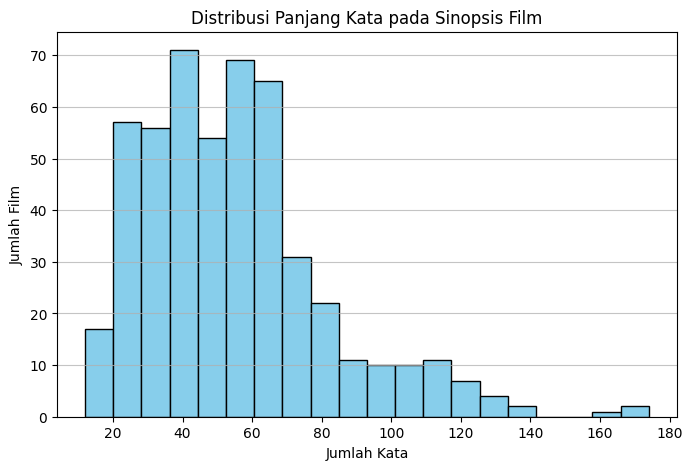

In [5]:
plt.figure(figsize=(8, 5))
plt.hist(df['word_count'], bins=20, color='skyblue', edgecolor='black')
plt.title('Distribusi Panjang Kata pada Sinopsis Film')
plt.xlabel('Jumlah Kata')
plt.ylabel('Jumlah Film')
plt.grid(axis='y', alpha=0.75)

os.makedirs('../results', exist_ok=True)
plt.savefig('../results/fig_distribusi_panjang_sinopsis.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
df.sort_values('word_count').head(5)[['title', 'word_count']]

,title,word_count
161,Gods of Egypt,12
200,The Hunger Games: Mockingjay - Part 1,14
177,Turbo,14
44,Furious 7,14
100,The Curious Case of Benjamin Button,15


## 4. Karakter Khusus pada Teks

Karakter ini akan mempengaruhi tahap preprocessing, jadi perlu diketahui sejak awal.

In [7]:
print('Sinopsis dengan apostrof lengkung (’):', df['overview'].str.contains('’').sum())
print('Sinopsis dengan apostrof lurus (\'):', df['overview'].str.contains("'").sum())
print('Sinopsis dengan angka:', df['overview'].str.contains(r'\d').sum())
print('Sinopsis dengan karakter non-ASCII:', df['overview'].str.contains(r'[^\x00-\x7F]').sum())
print()
print('Contoh kata dengan apostrof lengkung:')
for teks in df[df['overview'].str.contains('’')]['overview'].head(3):
    print('-', re.search(r'\w+’\w*', teks).group())

Sinopsis dengan apostrof lengkung (’): 28
Sinopsis dengan apostrof lurus ('): 214
Sinopsis dengan angka: 103
Sinopsis dengan karakter non-ASCII: 81

Contoh kata dengan apostrof lengkung:
- Bond’s
- Man’s
- Earth’s


## 5. Kata yang Paling Sering Muncul (Teks Mentah)

Teks hanya diubah ke huruf kecil dan diambil bagian hurufnya saja. Belum ada stopword removal.

In [8]:
semua_kata = []
for teks in df['overview']:
    semua_kata += re.findall(r'[a-z]+', teks.lower())

hitung = Counter(semua_kata)
print('Total token  :', len(semua_kata))
print('Kata unik    :', len(hitung))

top20 = pd.DataFrame(hitung.most_common(20), columns=['kata', 'frekuensi'])
persen = top20['frekuensi'].sum() / len(semua_kata) * 100
print('Porsi 20 kata teratas: %.1f%% dari seluruh token' % persen)
top20

Total token  : 27990
Kata unik    : 6011
Porsi 20 kata teratas: 32.1% dari seluruh token


,kata,frekuensi
0,the,1768
1,to,974
2,a,956
3,and,857
4,of,784
5,his,451
6,in,434
7,is,366
8,s,317
9,with,254


## 6. Ukuran Kosakata Awal

Angka ini jadi pembanding untuk skenario S1 sampai S4 di tahap berikutnya.

In [9]:
kosakata_mentah = set()
for teks in df['overview']:
    kosakata_mentah.update(teks.split())

print('Kosakata unik (dipisah spasi saja, huruf besar/kecil dibedakan):', len(kosakata_mentah))
print('Kosakata unik (huruf kecil, hanya huruf)                       :', len(hitung))

Kosakata unik (dipisah spasi saja, huruf besar/kecil dibedakan): 8181
Kosakata unik (huruf kecil, hanya huruf)                       : 6011


## 7. Contoh Data

In [10]:
pd.set_option('display.max_colwidth', 120)
df[['title', 'overview']].head(3)

,title,overview
0,Avatar,"In the 22nd century, a paraplegic Marine is dispatched to the moon Pandora on a unique mission, but becomes torn bet..."
1,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, has come back to life and is headed to the edge of the Earth with Will T..."
2,Spectre,A cryptic message from Bond’s past sends him on a trail to uncover a sinister organization. While M battles politica...


## Kesimpulan EDA

- Dataset berisi **500 film** dengan 2 kolom (`title`, `overview`). Tidak ada missing value, dan tidak ada baris, judul, maupun sinopsis yang duplikat.
- Panjang sinopsis rata-rata **54,9 kata** (median 51,5), terpendek 12 kata dan terpanjang 174 kata. Ada **14 sinopsis** yang kurang dari 20 kata, sehingga sebagian film hanya punya sedikit kata untuk dicocokkan.
- Pada teks mentah, **20 kata teratas semuanya kata fungsi** (the, to, a, and, of, ...) atau sisa apostrof `s`, dan menyumbang **32,1%** dari 27.990 token. Ini alasan stopword removal (S3) diuji pada eksperimen.
- Kosakata unik berjumlah **8.181** jika teks hanya dipisah spasi (huruf besar/kecil dibedakan, tanda baca menempel), dan turun menjadi **6.011** setelah huruf kecil dan hanya huruf. Selisih ini menunjukkan pengaruh S1 vs S2 pada ukuran kosakata.
- Karakter khusus ditemukan pada banyak sinopsis: apostrof lengkung (’) di 28 sinopsis, apostrof lurus (') di 214, angka di 103, dan karakter non-ASCII di 81.

**Yang harus ditangani di Tahap 2 (`preprocess.py`):**
1. Apostrof (lengkung maupun lurus) dihapus tanpa menyisakan spasi, atau token satu huruf dibuang, supaya "Bond’s" tidak menjadi "bond" dan "s".
2. Angka dan tanda baca dibersihkan pada S2 dan seterusnya.
3. Sinopsis pendek (12-19 kata) dicatat sebagai salah satu kategori penyebab kegagalan pada analisis di Tahap 6.